# Willett et al. 2023 - Exploring the Source Data

**A high-performance speech neuroprosthesis** (Nature 620, 1031-1036).

- [Willett et al., Nature 620, 1031-1036 (2023)](https://doi.org/10.1038/s41586-023-06377-x)
- Dryad: [doi:10.5061/dryad.x69p8czpq](https://datadryad.org/dataset/doi:10.5061/dryad.x69p8czpq)
- Code: https://github.com/fwillett/speechBCI

Subject **T12** (BrainGate2) had four 64-channel microelectrode arrays (256 channels total) implanted in the left hemisphere: two in **area 6v** (ventral precentral gyrus) and two in **area 44** (inferior frontal gyrus, part of Broca's area). All binned neural features use **20 ms bins (50 Hz)**.

<img src="assets/experiment_example.png" alt="The task monitor during a go period: the cued sentence above the green square, with the block and trial counter and the microphone in front" width="760">

*The task monitor during a go period (supplementary video): the cued sentence stays above the square, which has turned green, while T12 attempts to speak it into the microphone. The counter shows block 18, trial 5.*

This notebook reads the **raw source `.mat` files** through `utils.py`, focusing on the **sentence-production** data (the curated scope for this project). It loads the variables one session's plots need and subsamples for plotting to stay lightweight.

In [1]:
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import whosmat

from neuralshed.datasets.utils import dataset_dir
from neuralshed.datasets.willet_2023 import utils
from neuralshed.datasets.willet_2023.study import Willett2023Sentences

# reads ./.env into os.environ
load_dotenv()

s = Willett2023Sentences(path=dataset_dir("willet_2023") / "data")
s.download()
root = s.path
print("Study folder:", root)

print("Neural bin size:", utils.BIN_SIZE_S, "s  (", utils.SAMPLING_RATE_HZ, "Hz )")
print("Signal types:")
for k, v in utils.SIGNAL_TYPES.items():
    print(f"  {k:9s} {v}")
print("\nElectrode arrays (file-order columns in the .mat files, array-order columns in the Study rows):")
for name in utils.ARRAY_ORDER:
    source_columns = utils.ARRAY_CHANNELS[name]
    study_columns = utils.STUDY_ARRAY_SLICES[name]
    contiguous = source_columns[-1] - source_columns[0] == 63
    source_text = f"{source_columns[0]}-{source_columns[-1]}" if contiguous else "split"
    print(f"  {name:18s} file {source_text:8s} array {study_columns.start}-{study_columns.stop - 1}")

2026-10-15 12:09:26 - INFO - neuralset.events.study:463 - Success: Study downloaded to /Volumes/seagate_0/tether/datasets/willet_2023/data/Willett2023Sentences.


2026-10-15 12:09:29 - INFO - neuralset.events.study:85 - Permissions set for /Volumes/seagate_0/tether/datasets/willet_2023/data/Willett2023Sentences (skipped 0 non-owned items).


Study folder: /Volumes/seagate_0/tether/datasets/willet_2023/data/Willett2023Sentences
Neural bin size: 0.02 s  ( 50.0 Hz )
Signal types:
  spikePow  Spike band power -- mean of squared high-pass filtered voltages (250 Hz cutoff), uV^2.
  tx1       Threshold crossings at -3.5xRMS (binned counts, 20 ms bins).
  tx2       Threshold crossings at -4.5xRMS (binned counts, 20 ms bins).
  tx3       Threshold crossings at -5.5xRMS (binned counts, 20 ms bins).
  tx4       Threshold crossings at -6.5xRMS (binned counts, 20 ms bins).

Electrode arrays (file-order columns in the .mat files, array-order columns in the Study rows):
  dorsal_6v          file 32-95    array 0-63
  ventral_6v         file split    array 64-127
  dorsal_44          file 160-223  array 128-191
  ventral_44         file split    array 192-255


## Sessions overview

The sentence-production data spans 24 sessions (Apr-Aug 2022). `session_summary` reads each file and reports trial counts, recording length, block counts and speaking mode.

In [2]:
print("sentences sessions:", len(utils.list_sessions(root)))

summary_df = pd.DataFrame(utils.session_summary(root))
summary_df

sentences sessions: 24


,session,n_trials,n_timesteps,duration_min,n_blocks,speaking_mode
0,t12.2022.04.28,300,297962,99.3,15,attempted speaking
1,t12.2022.05.05,380,354533,118.2,19,attempted speaking
2,t12.2022.05.17,490,309501,103.2,24,attempted speaking
3,t12.2022.05.19,250,133515,44.5,12,attempted speaking
4,t12.2022.05.24,475,245574,81.9,13,attempted speaking
5,t12.2022.05.26,450,233723,77.9,12,attempted speaking
6,t12.2022.06.02,515,247104,82.4,14,attempted speaking
7,t12.2022.06.07,490,241955,80.7,12,attempted speaking
8,t12.2022.06.14,450,228438,76.1,11,attempted speaking
9,t12.2022.06.16,450,226774,75.6,11,attempted speaking


## Load one sentences session

We take the first session, read the variable shapes and dtypes from the file header with `whosmat`, then load only the variables the plots below need (one threshold stream, the audio envelope and the trial fields) instead of the whole 1.5 GB file. Continuous neural arrays have shape `(T, 256)` where `T` is the number of 20 ms bins and the 256 columns span the four 64-channel arrays, interleaved in file order as the readme grids show (`utils.ARRAY_GRIDS`).

In [3]:
session = utils.list_sessions(root)[0]
path = utils.sentences_file(root, session)

# shapes and dtypes from the file header, nothing loaded yet
variables = {name: (shape, dtype) for name, shape, dtype in whosmat(str(path))}
for name in list(utils.SIGNAL_TYPES) + ["audioFeatures", "audioEnvelope", "audio"]:
    shape, dtype = variables[name]
    print(f"  {name:13s} shape={shape}  dtype={dtype}")

# load only what the plots need
data = utils.load_variables(
    path,
    [
        "tx1",
        "audioEnvelope",
        "delayTrialEpochs",
        "goTrialEpochs",
        "trialDelayTimes",
        "sentences",
        "sentenceDurations",
        "blockTypes",
        "speakingMode",
    ],
)
print("\nSession:", session, "| speaking mode:", data["speakingMode"])

# per-array selection through the readme grids (file-order columns)
print("\nPer-array selection of tx1:")
for name in utils.ARRAY_ORDER:
    sub = utils.get_array_signal(data, "tx1", name)
    print(f"  {name:18s} -> {sub.shape}")


  spikePow      shape=(297962, 256)  dtype=single
  tx1           shape=(297962, 256)  dtype=uint8
  tx2           shape=(297962, 256)  dtype=uint8
  tx3           shape=(297962, 256)  dtype=uint8
  tx4           shape=(297962, 256)  dtype=uint8
  audioFeatures shape=(297962, 42)  dtype=double
  audioEnvelope shape=(297962, 1)  dtype=double
  audio         shape=(1, 15)  dtype=cell



Session: t12.2022.04.28 | speaking mode: attempted speaking

Per-array selection of tx1:
  dorsal_6v          -> (297962, 64)
  ventral_6v         -> (297962, 64)
  dorsal_44          -> (297962, 64)
  ventral_44         -> (297962, 64)


## A few trials

Each trial has a delay period (red square) and a go period (green square = attempt to speak the sentence). `extract_trials` returns the epochs as 0-based 20 ms bins with an exclusive end (the source stores 1-based inclusive epochs), so `data[go_start:go_end]` is the go period. The `blockTypes` field records sentence source and whether real-time closed-loop ("CL") decoding occurred.

In [4]:
trials = utils.extract_trials(data, "sentences")
print(f"{len(trials)} trials. First 5:\n")
trials_df = pd.DataFrame(trials[:5])[
    ["delay_start", "delay_end", "go_start", "go_end", "delay_time", "duration_bins", "sentence"]
]
# block info is per-bin; show block types present
print("block types:", sorted(set(np.atleast_1d(np.asarray(data["blockTypes"])).tolist())))
trials_df

300 trials. First 5:

block types: ['OL Open WebText']


,delay_start,delay_end,go_start,go_end,delay_time,duration_bins,sentence
0,0,400,400,879,8.04,479,Nuclear rockets can destroy airfields with ease.
1,879,1293,1293,1740,8.26,447,The best way to learn is to solve extra problems.
2,1740,2172,2172,2727,8.64,555,The spray will be used in first division match...
3,2727,3160,3160,3622,8.64,462,Our experiment's positive outcome was unexpected.
4,3622,4040,4040,4389,8.36,349,Alimony harms a divorced man's wealth.


## Binned neural activity around one trial

Heatmap of threshold-crossing (`tx1`) activity across all 256 channels around a single trial's delay+go window, with the columns converted from file order to array order (`utils.to_array_order`) so that each array is one contiguous block, as in the Study rows. Horizontal lines separate the four arrays, the vertical line marks the go cue.

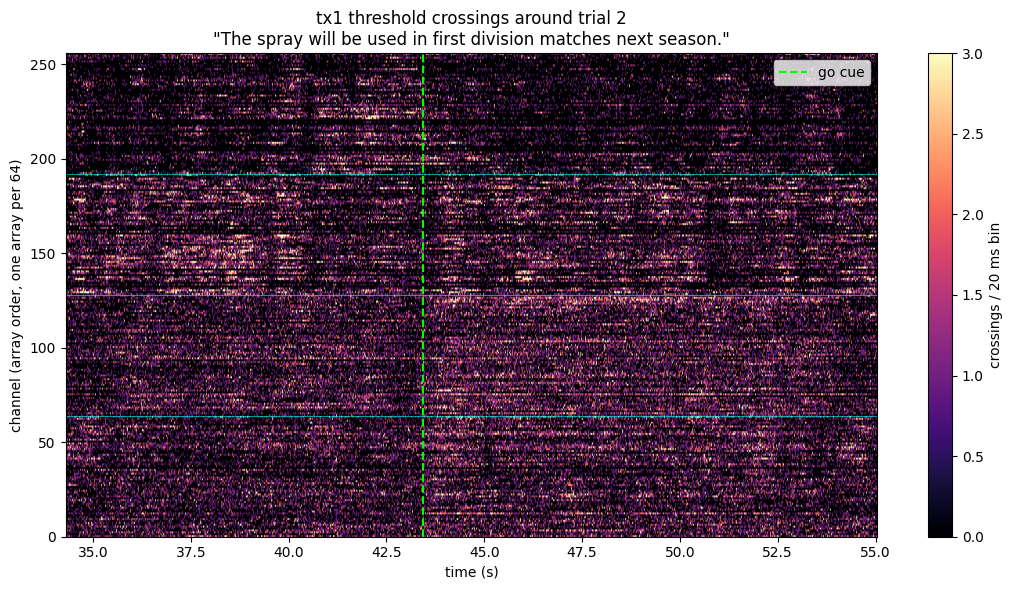

In [5]:
tr = trials[2]
pad = 25  # bins of context on each side
t0 = max(tr["delay_start"] - pad, 0)  # 0-based bins, t1 exclusive
t1 = tr["go_end"] + pad

tx1 = utils.to_array_order(np.asarray(data["tx1"])[t0:t1, :])  # (window, 256), array order

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(tx1.T, aspect="auto", origin="lower", cmap="magma",
               extent=[t0 * utils.BIN_SIZE_S, t1 * utils.BIN_SIZE_S, 0, 256],
               vmax=np.percentile(tx1, 99))
for name in utils.ARRAY_ORDER[:-1]:
    ax.axhline(utils.STUDY_ARRAY_SLICES[name].stop, color="cyan", lw=0.8, alpha=0.6)
ax.axvline(tr["go_start"] * utils.BIN_SIZE_S, color="lime", lw=1.5, ls="--", label="go cue")
ax.set_xlabel("time (s)")
ax.set_ylabel("channel (array order, one array per 64)")
ax.set_title(f"tx1 threshold crossings around trial 2\n\"{tr['sentence']}\"")
ax.legend(loc="upper right")
fig.colorbar(im, ax=ax, label="crossings / 20 ms bin")
plt.tight_layout()
plt.show()

## Audio envelope for the same trial

The audio envelope (microphone volume, downsampled to 50 Hz and aligned to the neural data) rises during the go period as T12 attempts to speak.

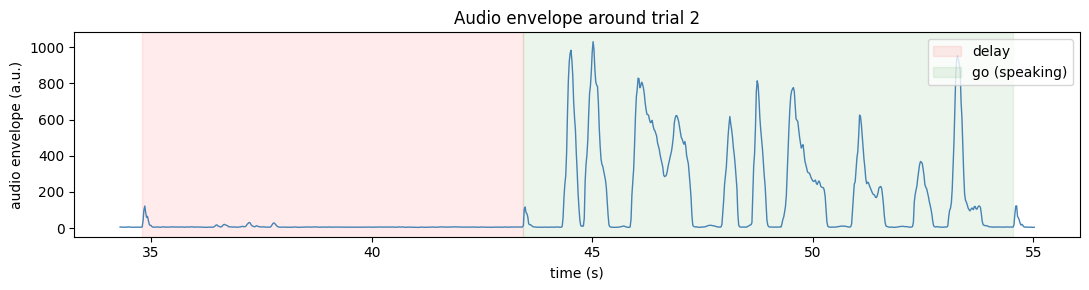

In [6]:
env = np.asarray(data["audioEnvelope"])[t0:t1]
t_axis = np.arange(t0, t1) * utils.BIN_SIZE_S

fig, ax = plt.subplots(figsize=(11, 3))
ax.plot(t_axis, env, color="steelblue", lw=1.0)
ax.axvspan(tr["delay_start"] * utils.BIN_SIZE_S, tr["go_start"] * utils.BIN_SIZE_S,
           color="red", alpha=0.08, label="delay")
ax.axvspan(tr["go_start"] * utils.BIN_SIZE_S, tr["go_end"] * utils.BIN_SIZE_S,
           color="green", alpha=0.08, label="go (speaking)")
ax.set_xlabel("time (s)")
ax.set_ylabel("audio envelope (a.u.)")
ax.set_title("Audio envelope around trial 2")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()

## Notes

- **Scope**: this project's curated scope is **sentences only** (no decoder/competition data), and reads **raw source** files only.
- **Neural features**: 5 signal types (`spikePow` + `tx1`-`tx4`), each `(T, 256)` at 50 Hz, with the 256 channels spread over 4 arrays (2x area 6v, 2x area 44). The `.mat` files interleave the arrays (file order, readme grids in `utils.ARRAY_GRIDS`). The Study emits array order, one contiguous block of 64 per array (`utils.CHANNEL_ORDER`).
- **Speaking modes**: sessions are either `attempted speaking` (vocalized) or `attempted nonvocal speaking` (mouthed).
- **Other archives** (not downloaded): `diagnosticBlocks` (cued single words), `tuningTasks` (orofacial / phonemes / 50-word set) and `competitionData` (per-trial go-period clips, whose block partition the Study carries as `original_split`).